In [8]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.2.3 | numpy 2.4.6


In [9]:
import os
FILE = 'tourism_dataset.csv'

if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Letakkan CSV di folder yang sama dengan notebook ini.')
print('Siap:', os.path.exists(FILE))

Siap: True


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style='whitegrid')

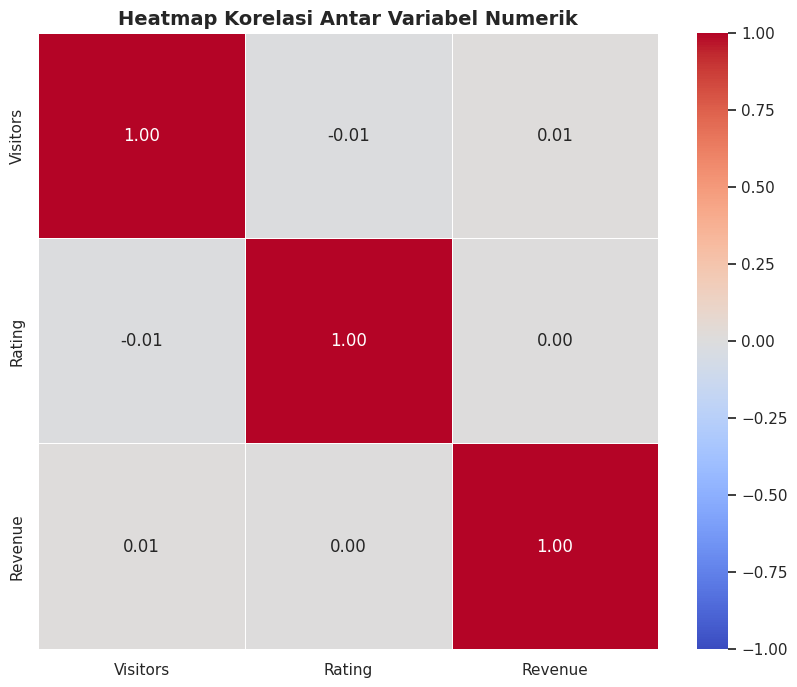

In [11]:
import pandas as pd

# Membaca dataset terlebih dahulu
df = pd.read_csv('tourism_dataset.csv')

# 1. Pilih hanya kolom numerik (kecuali ID jika ada)
kolom_num = df.select_dtypes(include=['number']).columns
if 'Location_ID' in kolom_num:
  kolom_num = kolom_num.drop('Location_ID')

# 2. Hitung matriks korelasi (menggunakan Pearson)
matrix_korelasi = df[kolom_num].corr()

# 3. Visualisasikan menggunakan Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    matrix_korelasi,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title(
    'Heatmap Korelasi Antar Variabel Numerik', fontsize=14, fontweight='bold'
)
plt.show()

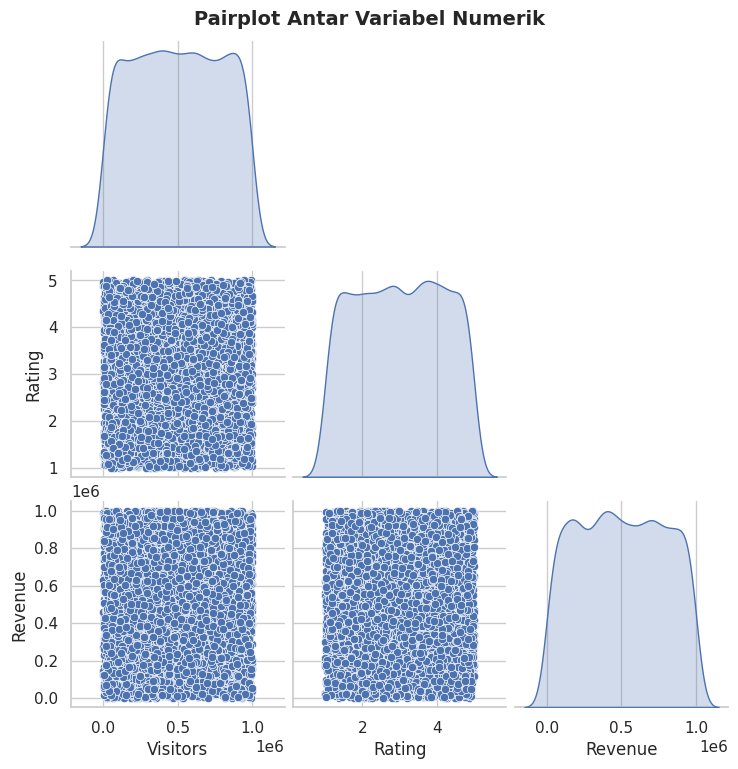

In [12]:
# Opsi A: Menggunakan Pairplot untuk melihat semua kombinasi numerik sekaligus
# (Opsional: tambahkan hue berdasarkan kolom kategorikal tertentu jika ada)
sns.pairplot(
    df[kolom_num], diag_kind='kde', corner=True
)  # corner=True agar tidak duplikat atas-bawah
plt.suptitle('Pairplot Antar Variabel Numerik', y=1.02, fontsize=14, fontweight='bold')
plt.show()

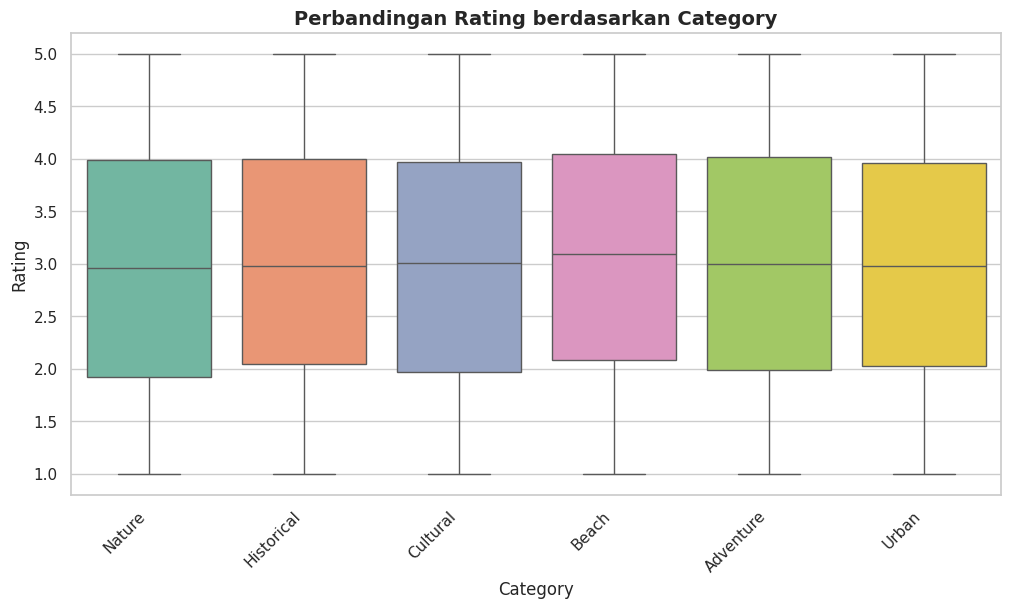

In [14]:
# Menyesuaikan nama kolom sesuai dengan dataset asli
kolom_kat_contoh = 'Category'  # Menggunakan 'Category' karena kolom 'Kategori' tidak ada
kolom_num_contoh = 'Rating'    # Tetap menggunakan 'Rating'

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x=kolom_kat_contoh,
    y=kolom_num_contoh,
    palette='Set2',
    hue=kolom_kat_contoh,
    legend=False,
)
plt.title(
    f'Perbandingan {kolom_num_contoh} berdasarkan {kolom_kat_contoh}',
    fontsize=14,
    fontweight='bold',
)
plt.xticks(rotation=45, ha='right')
plt.xlabel(kolom_kat_contoh)
plt.ylabel(kolom_num_contoh)
plt.show()

In [16]:
# Mencari rata-rata dan total dari kolom numerik berdasarkan kategori dan negara
hasil_agregasi = (
    df.groupby(['Category', 'Country'])[
        'Rating'
    ]
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .reset_index()
)

print('Tabel Agregasi Multivariat:')
display(hasil_agregasi)

Tabel Agregasi Multivariat:


,Category,Country,count,mean,median,min,max
0,Adventure,Australia,148,3.080878,3.135,1.03,5.00
1,Adventure,Brazil,160,3.140563,3.260,1.01,4.95
2,Adventure,China,139,2.860647,2.770,1.05,4.98
3,Adventure,Egypt,165,3.018606,2.950,1.00,5.00
4,Adventure,France,124,3.057581,3.070,1.00,4.98
5,Adventure,India,159,2.953459,2.930,1.01,4.98
6,Adventure,USA,142,2.938239,2.910,1.01,5.00
7,Beach,Australia,148,3.229865,3.340,1.05,4.97
8,Beach,Brazil,136,2.989559,3.040,1.06,4.98
9,Beach,China,135,3.069630,3.050,1.03,4.98
